# The CBD changing use

The City of Melbourne's Census of Land Use and Employment (CLUE) measures the floor space in every city block by what
it is used for, every year since 2002. It is published as a table keyed by `block_id`, with no shapes in it; the block
outlines are a separate file. In [Plotlay](https://www.getplotlay.com) the 603 blocks were taken from the council's
blocks file and keyed by `block_id`, the census table was linked from the council's portal with the census year as the
time axis, and formula columns worked out each block's office and apartments in 2002 and 2024 and the change.

This notebook reads only the files in `../data` and recomputes the numbers on the page.

In [1]:
import json
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
DATA = '../data'
pd.set_option('display.width', 140)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

## Sources and licence

Floor space per space use for blocks (CLUE, 2002 to 2024), CLUE blocks and road segments: City of Melbourne Open Data,
CC BY 4.0. Full credits in `NOTICE`.

**Held back cells.** The census leaves a cell blank where it would describe two businesses or fewer. Each row's total
still includes them. Blank cells are left blank here, never filled in.

In [2]:
d = pd.read_csv(f'{DATA}/clue/floor_space_by_use.csv')
d['year'] = d.census_year.astype(str).str[:4].astype(int)
cbd = d[d.clue_small_area == 'Melbourne (CBD)']
print(cbd.block_id.nunique(), 'CBD blocks,', d.year.min(), 'to', d.year.max())
cols = {'office': 'Office', 'residential_apartment': 'Apartments', 'commercial_accommodation': 'Hotels', 'student_accommodation': 'Student housing', 'total_floor_space_in_block': 'All floor space'}
tot = cbd.groupby('year')[list(cols)].sum().rename(columns=cols)
tot.loc[[2002, 2008, 2014, 2019, 2020, 2024]].round(0)

83 CBD blocks, 2002 to 2024


,Office,Apartments,Hotels,Student housing,All floor space
year,,,,,
2002,2745609.0,306545.0,228332.0,0.0,9397165.0
2008,3194201.0,505377.0,232573.0,0.0,10785603.0
2014,3025938.0,684440.0,261956.0,0.0,11430997.0
2019,3140760.0,1658110.0,305624.0,4857.0,13206021.0
2020,2888722.0,1704285.0,257693.0,4857.0,13373382.0
2024,2833795.0,2276604.0,427960.0,3033.0,14818195.0


Apartments, 2024 over 2002: 7.4 times
Office peak: 2008 3194201


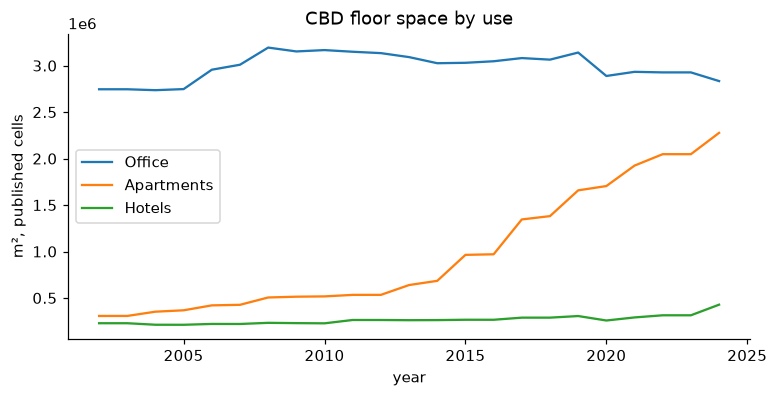

In [3]:
print('Apartments, 2024 over 2002:', round(tot.loc[2024, 'Apartments'] / tot.loc[2002, 'Apartments'], 1), 'times')
print('Office peak:', tot.Office.idxmax(), round(tot.Office.max()))
ax = tot[['Office', 'Apartments', 'Hotels']].plot(figsize=(8, 3.6)); ax.set_ylabel('m², published cells'); ax.set_title('CBD floor space by use')
plt.show()

## The blocks, as Plotlay worked them out

`blocks.geojson` is Plotlay's export of the Blocks layer, keyed by `block_id`, with the formula columns
`office_2002`, `office_2024`, `office_change`, `apartments_change`, `hotels_change`, `student_change` and
`homes_hotels_students_change` (`apartments_change + coalesce(hotels_change, 0) + coalesce(student_change, 0)`). A
change is empty where a year's figure is held back. Below, the same changes again from the census table.

In [4]:
b = gpd.read_file(f'{DATA}/geometry/blocks.geojson')
names = pd.read_csv(f'{DATA}/clue/block_names.csv').set_index('block_id').name
for c in ['office_change', 'apartments_change', 'homes_hotels_students_change']: b[c] = pd.to_numeric(b[c])
a, z = cbd[cbd.year == 2002].set_index('block_id'), cbd[cbd.year == 2024].set_index('block_id')
again = pd.DataFrame({'office_change': z.office - a.office, 'apartments_change': z.residential_apartment - a.residential_apartment})
again['living'] = again.apartments_change + (z.commercial_accommodation - a.commercial_accommodation).fillna(0) + (z.student_accommodation - a.student_accommodation).fillna(0)
m = b.set_index(b.key.astype(int)).join(again.add_suffix('_py'), how='inner')
print('largest difference, Plotlay against pandas:', float((m.office_change - m.office_change_py).abs().max()), 'm²')

largest difference, Plotlay against pandas: 0.0 m²


In [5]:
c = b[b.region_name == 'Melbourne (CBD)'].copy()
c['name'] = c.key.astype(int).map(names)
known = c.dropna(subset=['office_change', 'homes_hotels_students_change'])
print(len(known), 'CBD blocks with office and apartments published in both years')
big = known[(known.office_change < -5000) & (known.homes_hotels_students_change > 5000)].sort_values('office_change')
print(len(big), 'lost over 5,000 m² of office and gained over 5,000 m² of homes, hotels or student rooms:',
      f'{-big.office_change.sum():,.0f} m² of office out, {big.homes_hotels_students_change.sum():,.0f} m² in')
big[['key', 'name', 'office_change', 'apartments_change', 'homes_hotels_students_change']]

41 CBD blocks with office and apartments published in both years
9 lost over 5,000 m² of office and gained over 5,000 m² of homes, hotels or student rooms: 143,008 m² of office out, 365,305 m² in


,key,name,office_change,apartments_change,homes_hotels_students_change
57,32,"Collins St, William St to King St",-33043.0,16503.0,16503.0
261,25,"Collins St, Swanston St to Elizabeth St",-30005.0,12688.0,12688.0
247,38,"Collins St, Exhibition St to Spring St",-18864.0,10776.0,10776.0
263,74,"Lonsdale St, Elizabeth St to Queen St",-16658.0,57877.0,86528.0
252,97,"La Trobe St, Victoria St to Mackenzie St",-12420.0,102021.0,102021.0
257,87,"La Trobe St, Russell St to Exhibition St",-11185.0,54289.0,54289.0
254,58,"Bourke St, Spring St to Exhibition St",-8478.0,4618.0,12457.0
33,68,"Lonsdale St, Spring St to Exhibition St",-7309.0,16986.0,22096.0
460,93,"La Trobe St, A'Beckett St to Queen St",-5046.0,47947.0,47947.0


## Read it carefully

- These are blocks, not buildings: office falling and apartments rising in the same block does not show that one
  building changed use. A tower can go up beside an office building.
- Held back cells stay blank, so a block where a year is held back has no change worked out.
- For about half the blocks the 2023 figures repeat 2022's.